In [9]:
import numpy as np
import pandas as pd

In [10]:
df = pd.read_csv("house_price_mlr.csv")
print( df.head ())
print( df.shape )
print(df.info())
print( df.isnull().sum())

   House_ID  Area_sqft  Bedrooms  Bathrooms  Age_years  Distance_km  Parking  \
0         1        850         2          1         18         12.5        1   
1         2        900         2          2         15         11.8        1   
2         3        950         2          2         12         10.5        1   
3         4       1000         2          2         10          9.8        1   
4         5       1050         3          2          9          9.2        1   

   Locality_Rating  Price_Lakh  
0                5          42  
1                6          47  
2                6          51  
3                7          56  
4                7          61  
(20, 9)
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   House_ID         20 non-null     int64  
 1   Area_sqft        20 non-null     int64  
 2   Bedrooms         20 non-null     

In [11]:
print(df.describe())

       House_ID    Area_sqft   Bedrooms  Bathrooms  Age_years  Distance_km  \
count  20.00000    20.000000  20.000000  20.000000  20.000000     20.00000   
mean   10.50000  1325.000000   3.050000   2.500000   5.800000      6.93500   
std     5.91608   295.803989   0.686333   0.688247   4.926833      2.77873   
min     1.00000   850.000000   2.000000   1.000000   0.000000      3.20000   
25%     5.75000  1087.500000   3.000000   2.000000   2.000000      4.72500   
50%    10.50000  1325.000000   3.000000   2.500000   4.500000      6.50000   
75%    15.25000  1562.500000   3.250000   3.000000   8.250000      8.82500   
max    20.00000  1800.000000   4.000000   4.000000  18.000000     12.50000   

         Parking  Locality_Rating  Price_Lakh  
count  20.000000        20.000000   20.000000  
mean    1.650000         8.200000   87.900000  
std     0.587143         1.472556   29.666391  
min     1.000000         5.000000   42.000000  
25%     1.000000         7.000000   64.000000  
50%     2

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

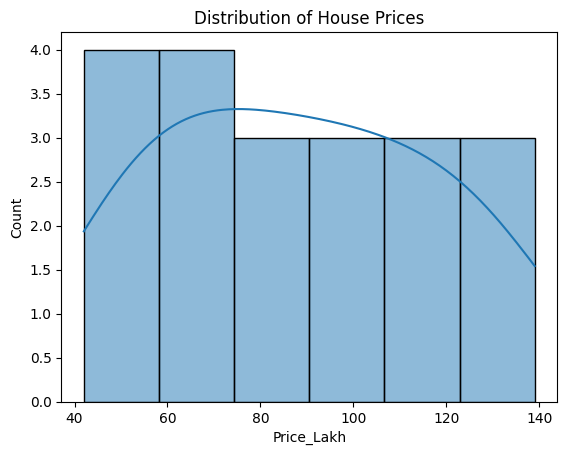

In [13]:
sns.histplot(df["Price_Lakh"], kde=True)
plt.title("Distribution of House Prices")
plt.show()

Price_Lakh         1.000000
Area_sqft          0.998901
Locality_Rating    0.953468
Bedrooms           0.902395
Bathrooms          0.894472
Parking            0.871129
Age_years         -0.926662
Distance_km       -0.976356
Name: Price_Lakh, dtype: float64


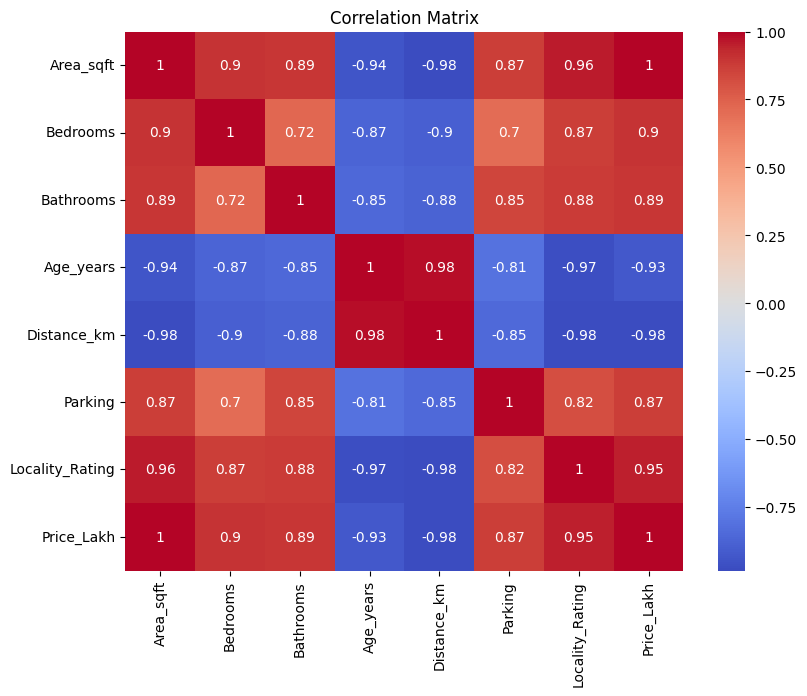

In [14]:
corr = df.drop(columns=["House_ID"]).corr()
print(corr["Price_Lakh"].sort_values(ascending=False))

plt.figure(figsize=(9,7))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()


In [15]:
X = df.drop(columns=["House_ID", "Price_Lakh"])
y = df["Price_Lakh"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Number of training observations:", len(X_train))
print("Number of testing observations:", len(X_test))

Number of training observations: 16
Number of testing observations: 4


In [16]:
from sklearn.linear_model import LinearRegression

In [17]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficients:")

for feature, coef in zip(X.columns, model.coef_):
    print(feature, coef)


Intercept: -142.89876389899175
Coefficients:
Area_sqft 0.13359289698635243
Bedrooms 1.682536444749799
Bathrooms 1.049765702315839
Age_years -0.17017375350383177
Distance_km 5.387479391778719
Parking 0.4863439362235286
Locality_Rating 1.1358130818915497


In [18]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Residual": y_test.values - y_pred
})

print(comparison)

   Actual   Predicted  Residual
0      42   45.515811 -3.515811
1     126  126.721670 -0.721670
2     115  115.827630 -0.827630
3      47   51.120321 -4.120321


In [19]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [20]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 2.2963579907222282
MSE: 7.635937553178859
RMSE: 2.7633200236633577
R²: 0.9947779534599563


In [21]:
n = X_test.shape[0]
p = X_test.shape[1]
adjusted_r2 = 1 - (1-r2) * (n-1)/(n-p-1)
print("Adjusted R²:", adjusted_r2)

Adjusted R²: 1.0039165349050327


In [22]:
fitted_values = y_pred
residuals = y_test.to_numpy() - y_pred
print("Residual mean:", np.mean(residuals))

Residual mean: -2.2963579907222282


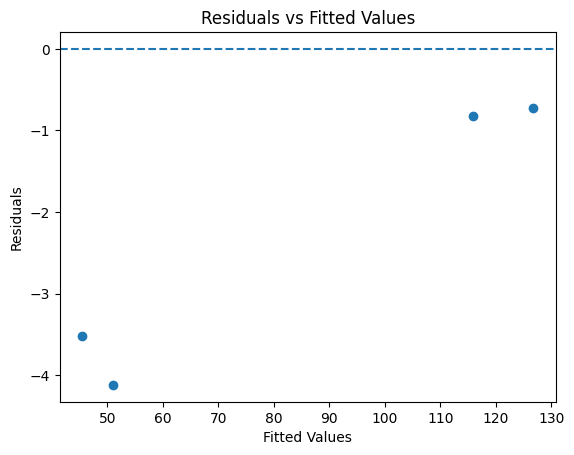

In [23]:
plt.scatter(fitted_values, residuals)
plt.axhline(0, linestyle="--")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")
plt.show()


In [24]:
from statsmodels.stats.stattools import durbin_watson

Durbin-Watson: 0.6109356184477426


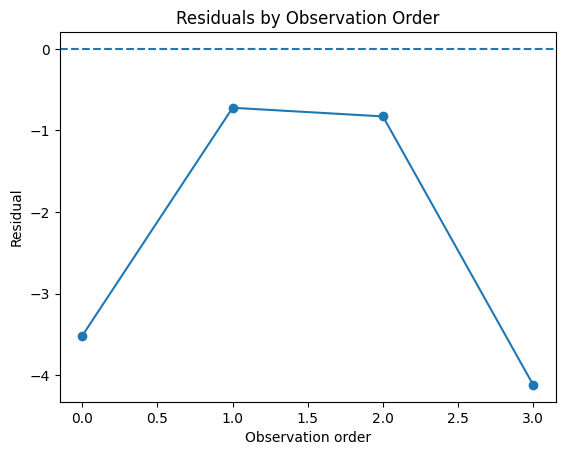

In [26]:
dw = durbin_watson(residuals)
print("Durbin-Watson:", dw)

plt.plot(np.arange(len(residuals)), residuals, marker="o")
plt.axhline(0, linestyle="--")
plt.xlabel("Observation order")
plt.ylabel("Residual")
plt.title("Residuals by Observation Order")
plt.show()


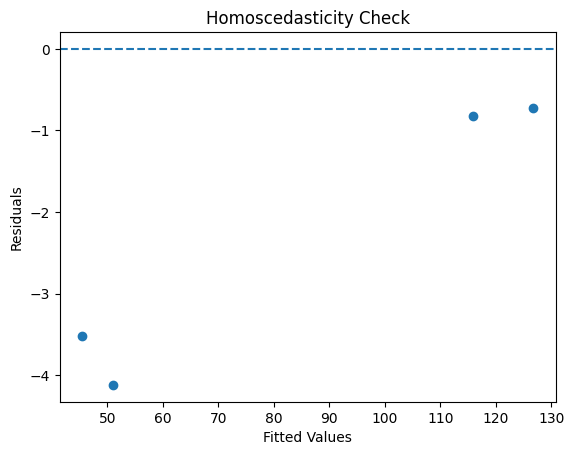

In [28]:
plt.scatter(fitted_values, residuals)
plt.axhline(0, linestyle="--")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Homoscedasticity Check")
plt.show()


In [30]:
from statsmodels.stats.diagnostic import het_breuschpagan

In [32]:
bp = het_breuschpagan(residuals, np.column_stack([np.ones(len(X_test)), X_test]))
print("LM statistic:", bp[0])
print("LM p-value:", bp[1])
print("F statistic:", bp[2])
print("F p-value:", bp[3])


LM statistic: 4.0
LM p-value: 0.779777408475716
F statistic: nan
F p-value: nan


c:\Users\Arjun\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\stats\diagnostic.py:1217: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y, x).fit()


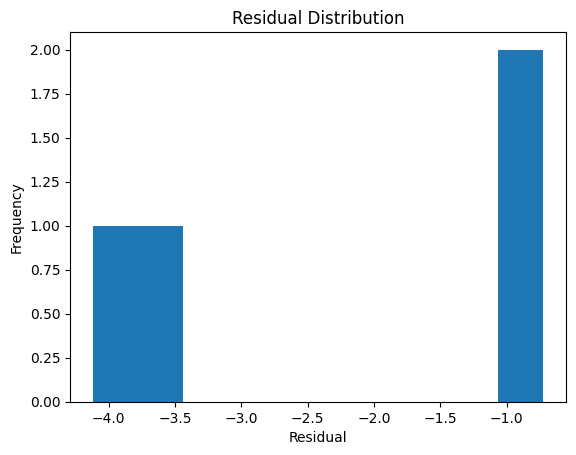

In [34]:
plt.hist(residuals, bins=10)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Residual Distribution")
plt.show()


In [36]:
import scipy.stats as stats

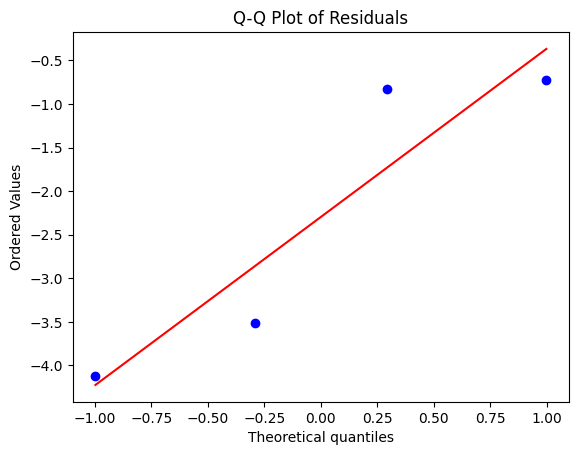

In [39]:
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot of Residuals")
plt.show()


In [41]:
from scipy.stats import shapiro

In [43]:
stat, p_value = shapiro(residuals)
print("Statistic:", stat)
print("p-value:", p_value)

Statistic: 0.8194735340720996
p-value: 0.14197780633702484


In [45]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [47]:
X_vif = X_train.copy()
X_vif = X_vif.astype(float)

vif = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

print(vif)


           Feature         VIF
0        Area_sqft  219.340792
1         Bedrooms    5.519243
2        Bathrooms    7.766242
3        Age_years  189.167635
4      Distance_km  640.634003
5          Parking    7.224924
6  Locality_Rating   30.572289


In [49]:
from sklearn.preprocessing import StandardScaler

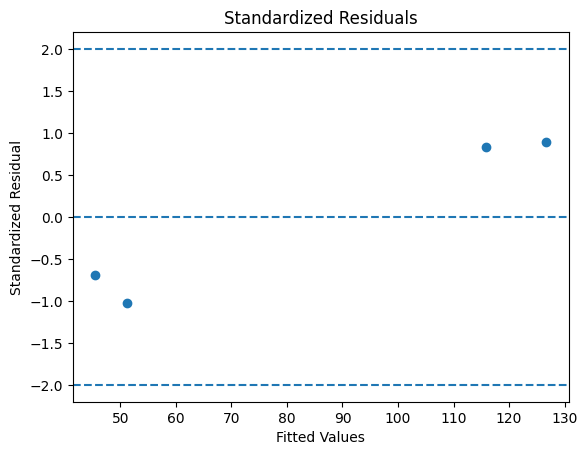

In [51]:
standardized_residuals = (
    residuals - np.mean(residuals)
) / np.std(residuals, ddof=1)

plt.scatter(fitted_values, standardized_residuals)
plt.axhline(0, linestyle="--")
plt.axhline(2, linestyle="--")
plt.axhline(-2, linestyle="--")
plt.xlabel("Fitted Values")
plt.ylabel("Standardized Residual")
plt.title("Standardized Residuals")
plt.show()


In [52]:
new_house = pd.DataFrame({
    "Area_sqft": [1500],
    "Bedrooms": [3],
    "Bathrooms": [3],
    "Age_years": [5],
    "Distance_km": [6],
    "Parking": [2],
    "Locality_Rating": [9]
})

prediction = model.predict(new_house)

print("Predicted price:", prediction[0], "Lakh")

Predicted price: 108.35650121435802 Lakh
